*Notebook 04 of 12 in `notebooks/scripts_text/`. Parameters: `analysis/scripts_text/config.yaml`; decisions and run notes: `analysis/scripts_text/LOG.md`. The static page `site/scripts/index.html` is built from the same outputs.*

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve().parents[1]   # notebooks/scripts_text -> repo root
sys.path.insert(0, str(REPO))

import warnings

import pandas as pd
import plotly.io as pio
from IPython.display import Markdown, display

from analysis.static_figures import use_static_figures

from analysis.scripts_text import s04_controls as step

use_static_figures()   # figures become static PNGs (they show on GitHub); interactive ones are on the static page
warnings.filterwarnings("ignore", category=RuntimeWarning)   # known 0/0 on very short arcs, handled downstream
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

## Step 4 · Controlling for genre, era and budget

**What we do.** Without controls, a comparison of successful and unsuccessful scripts mostly shows genre and
era words: action against drama, 1990s against 2010s. We control in two ways.

1. **Stratification.** Definition (C) already compares films only within the same genre × decade cell, and
   Step 5 also runs within single genres and decades where both groups have at least 30 scripts.
2. **Matching.** For each unprofitable script (gross below budget) we find the profitable script with the same
   primary genre, the same decade and the closest log budget, within a caliper of 0.5 standard deviations of
   log budget, without reusing a partner. Scripts with no partner inside the caliper are dropped and counted.

**Why match instead of randomly undersampling.** Scattertext compares *rates* per 10,000 words, so the two
groups don't need to be the same size; unequal sizes only make rare words noisier, which Step 7 tests.
Matching does something undersampling can't: it makes the two groups alike on budget, genre and era, so what
remains different is closer to the script itself.

**What it measures.** Balance, as standardised mean differences (SMD): the gap between the groups' means in
units of their pooled standard deviation. |SMD| below 0.1 is the usual rule of thumb for "balanced".

**What it misses.** Matching only balances what we match on. Stars, studio, marketing and release date stay
unbalanced. With 67 unprofitable scripts, the matched sample is small.

In [2]:
res = step.run()   # recomputes this step and saves its outputs

**Figure.** Standardised mean differences between unprofitable and profitable scripts, before (triangles) and after (circles) matching. Points inside the dotted lines are balanced.

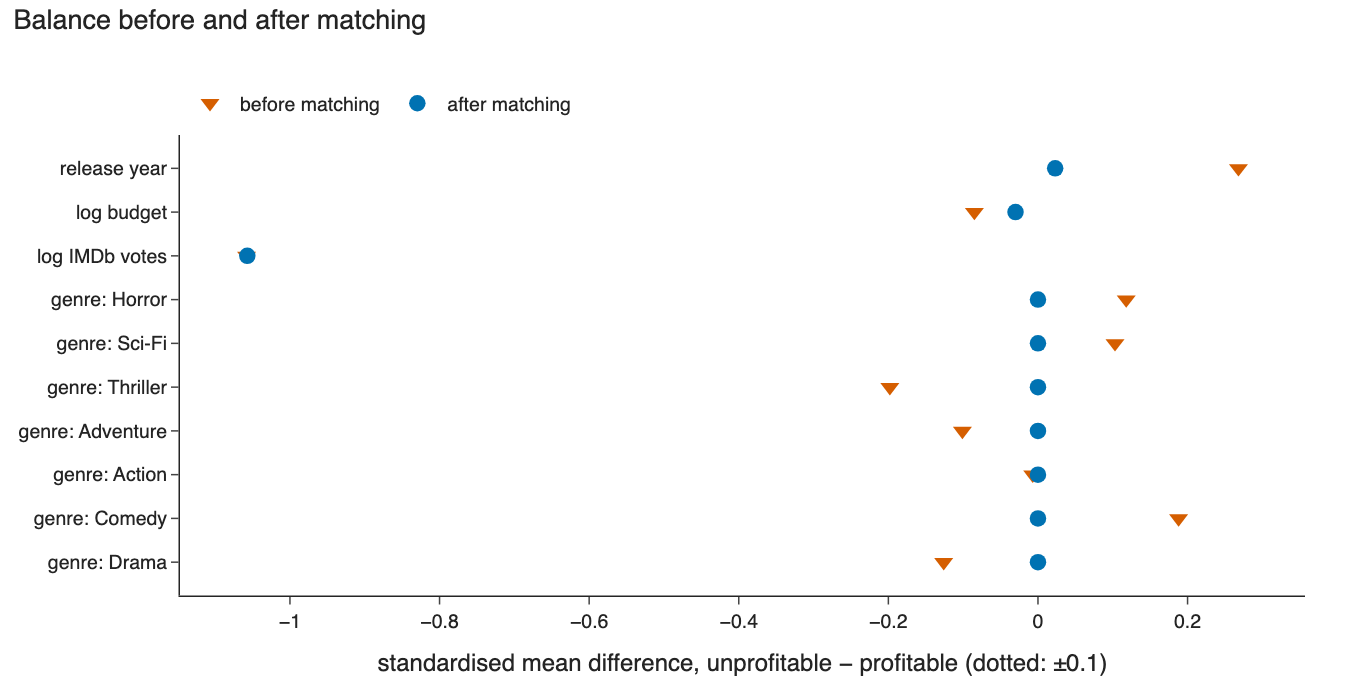

In [3]:
step.figures(res)["balance"].show()

**Table.** The same numbers as a table.

In [4]:
display(step.tables(res)["balance"])

,variable,SMD before,SMD after
0,release year,0.268,0.023
1,log budget,-0.085,-0.030
2,log IMDb votes,-1.058,-1.057
3,genre: Horror,0.118,0.000
4,genre: Sci-Fi,0.103,0.000
5,genre: Thriller,-0.198,0.000
6,genre: Adventure,-0.101,0.000
7,genre: Action,-0.007,0.000
8,genre: Comedy,0.188,0.000
9,genre: Drama,-0.126,0.000


**Plain-language reading** (generated from the saved numbers):

In [5]:
display(Markdown(step.reading(res)))

Of the 67 unprofitable scripts, 67 find a profitable partner in the same genre and decade with a log budget within 0.66 (that is 0.5 standard deviations); 0 have none and are dropped from the matched comparison. The median budget gap within a pair is 0.02 in log units (about 2%). On the variables we match on (year, budget, genre) the largest absolute standardised mean difference falls from 0.27 to 0.03. IMDb votes are deliberately not matched on, because votes come after release and partly measure success itself; their SMD stays at -1.06 (before: -1.06): unprofitable films are far less watched, so any word difference in the matched sample may also reflect popularity.